# Taller: Funciones de Activación

### Redes Neuronales — Sigmoid, Tanh, ReLU, Leaky ReLU, Softmax y sus derivadas con NumPy

**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 06-11-2026


> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller

Al finalizar este taller el estudiante será capaz de:

1. Programar con NumPy Sigmoid, Tanh, ReLU, Leaky ReLU y Softmax, y las **derivadas** de las cuatro primeras.
2. Leer en un gráfico dónde cada función **satura** (derivada ≈ 0) y relacionarlo con el **gradiente evanescente**.
3. Comprobar que, sin función de activación, una red con capa oculta se comporta como un **modelo lineal**.
4. Elegir la activación adecuada para las **capas ocultas** y para la **capa de salida** según la tarea.


## Datasets (sintéticos, sin valores nulos)

| Parte | Archivo | Filas | Entradas | Etiqueta |
| --- | --- | --- | --- | --- |
| A | estudiantes_aprobacion.csv | 200 estudiantes | horas_estudio, asistencia_pct | aprueba (1 = aprueba) |
| B | solicitudes_credito.csv | 200 solicitudes | ingresos_mensuales, deuda_total, historial_pagos | aprobado (1 = aprobado) |

Son los mismos archivos del taller de Arquitectura de Redes Neuronales.


## Estructura del taller

| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Librerías y función para graficar |
| A2 | Guiado | Sigmoid y su derivada |
| A3 | Guiado | Tanh, ReLU y Leaky ReLU con sus derivadas |
| A4 | Guiado | Gradiente que atraviesa varias capas |
| A5 | Guiado | Softmax con un ejemplo de triaje |
| A6 | Guiado | La red 2 → 2 → 1 de la clase anterior con distintas activaciones |
| B1–B5 | Autónomo | Red para solicitudes de crédito |

## Rúbrica de evaluación (10 puntos)

| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A6 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las preguntas de la Parte A | 1.5 |
| B1 · Datos y normalización | Código correcto + formas verificadas | 1.0 |
| B2 · Comparar activaciones | Bucle correcto con los pesos de la Parte B + tabla de accuracy + interpretación | 2.5 |
| B3 · Neuronas apagadas | Conteo correcto con ReLU y Leaky ReLU + explicación | 1.5 |
| B4 · Softmax de riesgo | Probabilidades correctas, suma 1, clase predicha + respuesta | 1.5 |
| B5 · Elegir la activación | Neuronas de salida, activación y justificación en los 3 escenarios | 2.0 |
| **Total** | | **10** |


# Parte A — Laboratorio Guiado: Las Funciones de Activación


## Bloque A1 · Librerías y función para graficar

* `z = np.linspace(-6, 6, 400)` crea 400 valores de z entre −6 y 6: el eje horizontal de todos los gráficos.
* Para no repetir código, la función `graficar()` dibuja **una función y su derivada** lado a lado.
Recibe la función, su derivada y un nombre.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 400)   # valores de z para los gráficos

def graficar(f, derivada, nombre):
    fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
    ejes[0].plot(z, f(z), color="#41BFBC", linewidth=3)
    ejes[0].set_title(nombre)
    ejes[1].plot(z, derivada(z), color="#E8BD30", linewidth=3)
    ejes[1].set_title("Derivada de " + nombre)
    for eje in ejes:
        eje.axhline(0, color="gray", linewidth=0.8)   # eje horizontal
        eje.axvline(0, color="gray", linewidth=0.8)   # eje vertical
        eje.set_xlabel("z")
        eje.grid(alpha=0.3)
    plt.show()


## Bloque A2 · Sigmoid y su derivada

$$\sigma(z) = \frac{1}{1 + e^{-z}} \qquad\qquad \sigma'(z) = \sigma(z)\,\left(1 - \sigma(z)\right)$$

* Rango (0, 1): se interpreta como probabilidad.
* La derivada es la **pendiente** de la curva: indica cuánto cambia σ(z) si z cambia un poco.
* **¿Para qué sirve?** No se usa para predecir, sino para **entrenar**: la corrección de cada peso se multiplica por $f'(z)$.
Si $f'(z) \approx 0$, el peso casi no cambia aunque la red se equivoque mucho.


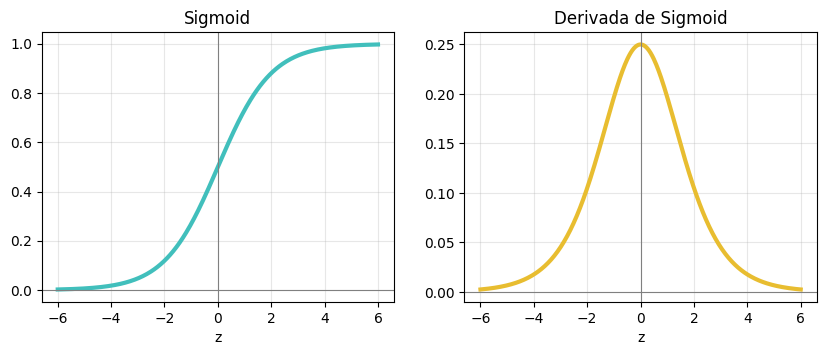

z = 0:  sigmoid = 0.500   derivada = 0.250
z = 2:  sigmoid = 0.881   derivada = 0.105
z = 4:  sigmoid = 0.982   derivada = 0.018
z = 6:  sigmoid = 0.998   derivada = 0.002


In [18]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def d_sigmoid(z):
    return sigmoid(z) * (1 - sigmoid(z))

graficar(sigmoid, d_sigmoid, "Sigmoid")

for valor in [0, 2, 4, 6]:
    print(f"z = {valor}:  sigmoid = {sigmoid(valor):.3f}   derivada = {d_sigmoid(valor):.3f}")


**Lectura:**

* La derivada máxima es **0.25** y ocurre en z = 0.
* Para z = 6 la curva está casi plana: la derivada vale 0.002. Esa zona se llama **saturación**.

**Preguntas** (respóndelas en tu notebook):

1. ¿Entre qué valores de z la derivada de Sigmoid es mayor que 0.1? Léelo en el gráfico.

En el grafico se observa que la derivada de Sigmoid supera el valor de 0.1 en el intervalo aproximado entre z = -2.2 y z = 2.2, alcanzando su valor maximo de 0.25 exactamente en z = 0.

2. Si una neurona recibe siempre z = 6, ¿cambiarán mucho sus pesos al entrenar? ¿Por qué?

Sus pesos apenas cambiaran durante el entrenamiento. Esto ocurre porque en z = 6 la funcion Sigmoid entra en su zona de saturacion, donde la curva es casi plana y su derivada es sumamente pequena (aproximadamente 0.002). Durante la retropropagacion, la correccion de cada peso se multiplica por dicha derivada, dando una actualizacion practicamente nula.


## Bloque A3 · Tanh, ReLU y Leaky ReLU con sus derivadas

| Función | Fórmula | Derivada |
| --- | --- | --- |
| Tanh | $\tanh(z)$ (ya existe: np.tanh) | $1 - \tanh^2(z)$ |
| ReLU | $\max(0, z)$ | $1$ si $z > 0$; $0$ si $z \leq 0$ |
| Leaky ReLU | $z$ si $z \geq 0$; $\alpha z$ si $z < 0$ | $1$ si $z \geq 0$; $\alpha$ si $z < 0$ |

* `np.where(condición, a, b)` devuelve `a` donde la condición es verdadera y `b` donde es falsa, elemento a elemento.
* En este taller usamos **α = 0.1** para que la pendiente negativa se vea en el gráfico.


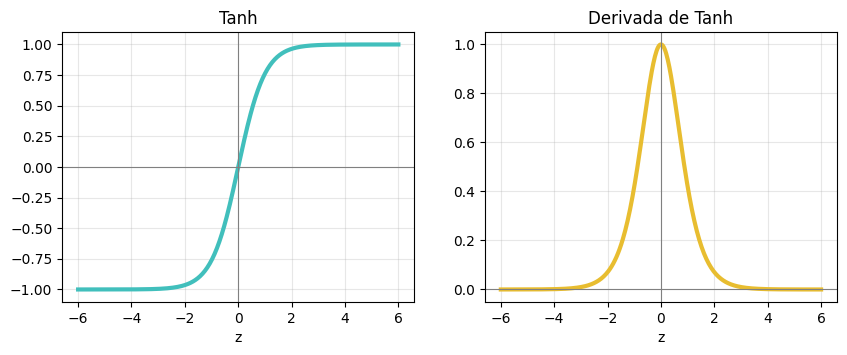

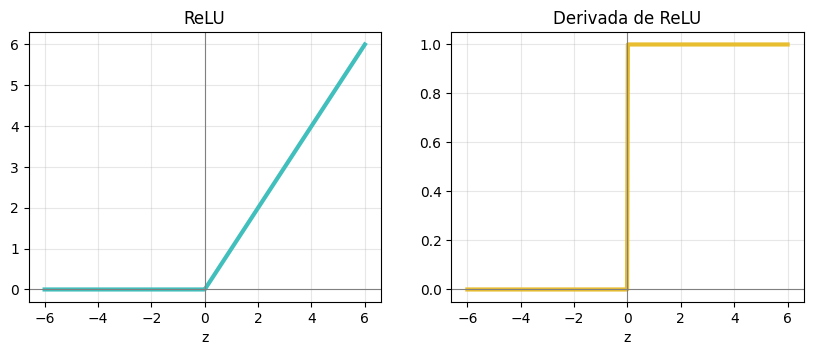

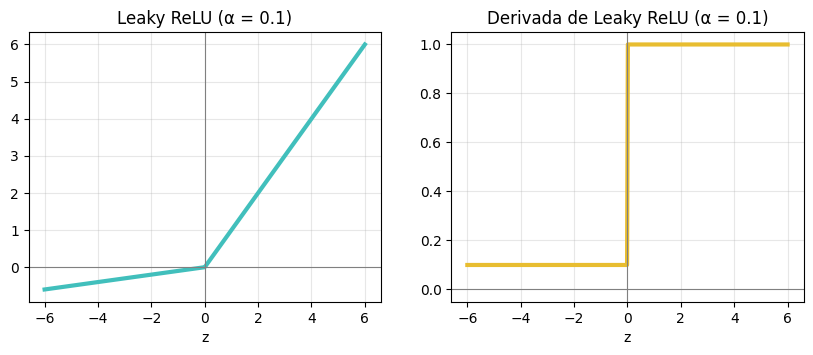

In [19]:
def d_tanh(z):
    return 1 - np.tanh(z) ** 2

def relu(z):
    return np.maximum(0, z)

def d_relu(z):
    return np.where(z > 0, 1.0, 0.0)

def leaky_relu(z, alpha=0.1):
    return np.where(z >= 0, z, alpha * z)

def d_leaky_relu(z, alpha=0.1):
    return np.where(z >= 0, 1.0, alpha)

graficar(np.tanh, d_tanh, "Tanh")
graficar(relu, d_relu, "ReLU")
graficar(leaky_relu, d_leaky_relu, "Leaky ReLU (α = 0.1)")


In [20]:
# Derivada de cada función en algunos valores de z
valores = np.array([-4.0, -1.0, 0.5, 4.0])
tabla = pd.DataFrame({
    "z": valores,
    "Sigmoid'": d_sigmoid(valores),
    "Tanh'": d_tanh(valores),
    "ReLU'": d_relu(valores),
    "LeakyReLU'": d_leaky_relu(valores),
})
tabla.round(3)


,z,Sigmoid',Tanh',ReLU',LeakyReLU'
0,-4.0,0.018,0.001,0.0,0.1
1,-1.0,0.197,0.420,0.0,0.1
2,0.5,0.235,0.786,1.0,1.0
3,4.0,0.018,0.001,1.0,1.0


**Lectura:**

* Tanh tiene derivada máxima **1** (cuatro veces la de Sigmoid), pero también satura: **su derivada** en z = 4 vale 0.001.
* ReLU tiene derivada **1** para cualquier z positivo: no satura. Para z negativo su derivada es **0**.
* Leaky ReLU nunca tiene derivada 0: para z negativo vale α = 0.1.

**Preguntas:**

1. ¿Qué funciones tienen derivada casi 0 en z = 4? ¿Y en z = −4?

En z = 4, las funciones Sigmoid y Tanh tienen una derivada casi igual a cero (0.017 y 0.001 respectivamente) debido a la saturacion positiva. En z = -4, las funciones Sigmoid, Tanh y ReLU tienen derivada casi cero o exactamente cero (ReLU devuelve 0 para todo valor negativo, Sigmoid 0.017 y Tanh 0.001), mientras que Leaky ReLU mantiene una derivada constante de 0.1.

2. ¿Por qué el problema de ReLU se llama «neurona muerta» (*Dying ReLU*) y no «saturación»?

Se llama neurona muerta porque cuando la entrada z cae en la region negativa (z <= 0), la funcion ReLU produce exactamente cero y su derivada es exactamente cero de forma plana, no asintotica. Si una neurona recibe entradas negativas para todos los datos del conjunto de entrenamiento, ningun gradiente podra atravesarla, impidiendo que sus pesos vuelvan a actualizarse y dejandola inactiva de forma irreversible. En contraste, la saturacion se refiere a curvas suaves donde la derivada disminuye gradualmente hacia cero pero sin ser identicamente nula.


## Bloque A4 · Gradiente que atraviesa varias capas

**Gradiente:** las correcciones de todos los pesos juntas, una por peso, calculadas a partir del error. Cada corrección se multiplica por $f'(z)$.

Al entrenar, la señal de error viaja **de la salida hacia atrás** y en cada capa se multiplica por la derivada
de la activación. Aquí usamos el **mejor caso** de cada función:

* Sigmoid: como máximo 0.25 por capa → `0.25 ** capas`.
* ReLU con z > 0: exactamente 1 por capa → `1.0 ** capas`.


In [21]:
capas = np.arange(1, 11)          # de 1 a 10 capas
senal_sigmoid = 0.25 ** capas
senal_relu = 1.0 ** capas

gradiente = pd.DataFrame({"capas": capas,
                          "Sigmoid (máx.)": senal_sigmoid.round(6),
                          "ReLU (z > 0)": senal_relu})
print(gradiente.to_string(index=False))


 capas  Sigmoid (máx.)  ReLU (z > 0)
     1        0.250000           1.0
     2        0.062500           1.0
     3        0.015625           1.0
     4        0.003906           1.0
     5        0.000977           1.0
     6        0.000244           1.0
     7        0.000061           1.0
     8        0.000015           1.0
     9        0.000004           1.0
    10        0.000001           1.0


**Lectura:** con Sigmoid, tras 5 capas queda como máximo 0.001 de la señal y tras 10 capas, una millonésima: las correcciones de las primeras capas son casi cero y casi no aprenden. Esto es el **gradiente evanescente** (*vanishing gradient*).

**Pregunta:** según esta tabla, ¿qué activación usarías en las capas ocultas de una red de 10 capas? ¿Por qué?

En las capas ocultas de una red de 10 capas se debe utilizar ReLU (o variantes como Leaky ReLU). Como muestra la tabla, para entradas positivas la derivada de ReLU es exactamente 1.0 en cada capa, lo que permite que la senal del gradiente se transmita sin atenuarse a traves de las 10 capas (1.0 elevado a la decima potencia es 1.0). En cambio, con Sigmoid la derivada maxima por capa es 0.25, por lo que tras 10 capas la senal se multiplica sucesivamente hasta quedar reducida a menos de una millonesima (0.000001), sufriendo de gradiente evanescente e impidiendo el aprendizaje de las primeras capas.


## Bloque A5 · Softmax con un ejemplo de triaje

$$\mathrm{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$$

* Recibe un vector con un **logit** por clase (el valor z de cada neurona de salida) y devuelve probabilidades que suman 1.
* Se resta el máximo antes de la exponencial para evitar desbordes; el resultado no cambia.
* Ejemplo ilustrativo: logits de un paciente para riesgo **Bajo / Medio / Alto**.


Probabilidades: [0.659 0.242 0.099]
Suma: 1.0
Clase predicha: Bajo


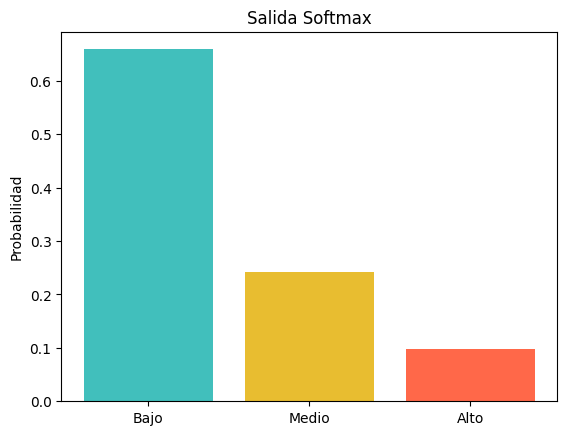

In [22]:
def softmax(z):
    z = z - np.max(z)      # estabilidad numérica
    e = np.exp(z)
    return e / e.sum()

clases = ["Bajo", "Medio", "Alto"]
logits = np.array([2.0, 1.0, 0.1])
p = softmax(logits)

print("Probabilidades:", p.round(3))       # [0.659 0.242 0.099]
print("Suma:", p.sum().round(3))           # 1.0
print("Clase predicha:", clases[np.argmax(p)])

plt.bar(clases, p, color=["#41BFBC", "#E8BD30", "#FF6849"])
plt.title("Salida Softmax")
plt.ylabel("Probabilidad")
plt.show()


In [23]:
# ¿Por qué restar el máximo? Logits grandes:
grandes = np.array([1000.0, 999.0, 998.0])
with np.errstate(over="ignore", invalid="ignore"):   # oculta el aviso de desborde
    sin_restar = np.exp(grandes) / np.exp(grandes).sum()
print("Sin restar el máximo:", sin_restar)                 # [nan nan nan]
print("Restando el máximo:  ", softmax(grandes).round(3))  # [0.665 0.245 0.09 ]


Sin restar el máximo: [nan nan nan]
Restando el máximo:   [0.665 0.245 0.09 ]


**Lectura:** `np.exp(1000)` es demasiado grande para la computadora (da `inf`); al restar el máximo los logits pasan a [0, −1, −2] y el resultado es el mismo que para [2, 1, 0]: [0.665 0.245 0.09].

**Preguntas:**

1. Suma 5 a los tres logits del ejemplo de triaje. ¿Cambian las probabilidades? ¿Por qué?

Las probabilidades no cambian en lo absoluto. Al sumar una constante a todos los logits, por ejemplo pasando de [2.0, 1.0, 0.1] a [7.0, 6.0, 5.1], en la formula de Softmax el termino exponencial e^(z+c) equivale a e^z multiplicado por e^c tanto en el numerador como en el denominador. Ese factor comun e^c se cancela en la division, conservando exactamente las mismas probabilidades relativas debido a la propiedad de invariancia ante traslaciones.

2. ¿Por qué Softmax solo se usa en la **capa de salida**?

Porque el proposito exclusivo de Softmax es normalizar un vector de puntajes finales en una distribucion de probabilidades mutuamente excluyentes cuya suma sea exactamente 1.0, lo cual es propio de la decision de clasificacion multiclase. En las capas ocultas no se busca que las neuronas compitan entre si sumando 1, sino que cada neurona extraiga caracteristicas y representaciones intermedias de forma independiente y sin restricciones globales.


## Bloque A6 · La red 2 → 2 → 1 de la clase anterior con distintas activaciones

Usamos la misma red, los **mismos pesos** y los mismos datos de la clase anterior. Solo cambia la activación de la
capa oculta; la salida sigue siendo Sigmoid. También probamos **sin activación** (`lineal`, que devuelve z sin cambios).

La función `forward_act()` es igual a `forward()` de la clase anterior, con un parámetro extra: `activacion`.


In [24]:
df = pd.read_csv("estudiantes_aprobacion.csv")
X = df[["horas_estudio", "asistencia_pct"]].values
y = df["aprueba"].values
X_norm = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

W1 = np.array([[3.0, -0.5], [-0.5, 3.0]])
b1 = np.array([-1.2, -1.2])
W2 = np.array([[2.0, 2.0]])
b2 = np.array([-2.0])

def lineal(z):
    return z               # sin activación

def forward_act(x, W1, b1, W2, b2, activacion):
    z1 = W1 @ x + b1
    a1 = activacion(z1)    # la activación oculta se recibe como parámetro
    z2 = W2 @ a1 + b2
    return sigmoid(z2)     # salida: probabilidad de aprobar


In [25]:
activaciones = {"ReLU": relu, "Leaky ReLU": leaky_relu, "Sigmoid": sigmoid,
                "Ninguna (lineal)": lineal, "Tanh": np.tanh}

resultados = []
for nombre, f in activaciones.items():
    y_hat = np.array([forward_act(x, W1, b1, W2, b2, f)[0] for x in X_norm])
    accuracy = ((y_hat >= 0.5).astype(int) == y).mean()
    resultados.append([nombre, accuracy])

pd.DataFrame(resultados, columns=["Activación oculta", "Accuracy"]).round(3)


,Activación oculta,Accuracy
0,ReLU,0.920
1,Leaky ReLU,0.900
2,Sigmoid,0.780
3,Ninguna (lineal),0.735
4,Tanh,0.665


**Lectura** (accuracy: rango 0 a 1 → 1 = deseado):

* ReLU 0.92 y Leaky ReLU 0.90: los pesos se diseñaron pensando en ReLU.
* **Sin activación: 0.735.** Sin función no lineal, la red equivale a una sola capa y su frontera es una recta.
* Tanh 0.665: para z < 0 devuelve valores **negativos** que restan a la salida.
* Ojo: con entrenamiento, cada activación encontraría sus propios pesos. Aquí solo vemos que la activación cambia la salida aunque los pesos sean iguales.


**Comprobación: sin activación, la capa oculta desaparece.**

Sin función de activación, las dos capas se pueden juntar en una sola neurona:
$W^* = W^{(2)}W^{(1)}$ y $b^* = W^{(2)}\mathbf{b}^{(1)} + b^{(2)}$. Lo comprobamos con los pesos de la red:


In [26]:
W_star = W2 @ W1           # pesos de la neurona equivalente
b_star = W2 @ b1 + b2      # sesgo de la neurona equivalente
print("W* =", W_star, "  b* =", b_star)   # [[5. 5.]]  [-6.8]

# Red 2 -> 2 -> 1 sin activación vs. una sola neurona con W* y b*
y_red = np.array([forward_act(x, W1, b1, W2, b2, lineal)[0] for x in X_norm])
y_neurona = np.array([sigmoid(W_star @ x + b_star)[0] for x in X_norm])
print("¿Mismas predicciones en los 200 estudiantes?", np.allclose(y_red, y_neurona))


W* = [[5. 5.]]   b* = [-6.8]
¿Mismas predicciones en los 200 estudiantes? True


**Preguntas de la Parte A:**

1. ¿Por qué la red «sin activación» no supera a la red con ReLU, aunque tenga una capa oculta?

Porque la composicion sucesiva de transformaciones lineales sigue siendo estrictamente una transformacion lineal. Sin una funcion de activacion no lineal en la capa oculta, la red de dos capas se colapsa matematicamente en un unico modelo lineal equivalente con una frontera de decision plana (una linea recta). Dado que el problema de aprobacion presenta una separacion no lineal con quiebre de tipo disyuntivo, la red sin activacion no puede amoldarse a dicha frontera y queda estancada en un accuracy de 73.5 por ciento, mientras que ReLU introduce no linealidades permitiendo alcanzar un 92.0 por ciento.

2. Leaky ReLU y ReLU dan casi el mismo accuracy. ¿En qué estudiantes podrían diferir sus predicciones?

Podrian diferir en aquellos estudiantes cuyas coordenadas se ubiquen muy cerca de la frontera de decision y que generen valores de z ligeramente negativos en la capa oculta. Con ReLU, cualquier valor negativo se apaga totalmente a cero, eliminando cualquier contribucion de esa neurona; con Leaky ReLU, ese valor negativo conserva una pequena senal residual multiplicada por alpha = 0.1, lo que puede desplazar levemente el valor de z2 en la salida hacia arriba o hacia abajo del umbral de corte de 0.5, modificando puntualmente la clase predicha.


# Parte B — Práctica Autónoma: Activaciones en una Red de Crédito

**Contexto:** una cooperativa de ahorro y crédito usa una red **3 → 3 → 1** para estimar si una solicitud se aprueba.
Los pesos ya están dados (fijados a mano, sin entrenar). Tu tarea es comparar activaciones y elegir la adecuada.
En tu notebook, escribe el código que reemplace cada `# TODO` de esta guía; las pistas en los comentarios indican qué usar.

| Variable | Qué mide | Rol |
| --- | --- | --- |
| ingresos_mensuales | Ingreso mensual del solicitante (USD) | Entrada x₁ |
| deuda_total | Deuda vigente total (USD) | Entrada x₂ |
| historial_pagos | Puntaje de historial de pagos (0 a 100) | Entrada x₃ |
| aprobado | 1 = aprobado, 0 = rechazado | Etiqueta |


## Bloque B1 · Datos y normalización


In [27]:
# TODO 1: carga solicitudes_credito.csv en df_b
df_b = pd.read_csv("solicitudes_credito.csv")
print("Dimensiones de df_b:", df_b.shape)
print("Valores nulos en total:", df_b.isnull().sum().sum())

# TODO 2: crea X_b con las 3 columnas de entrada (.values) e y_b con la columna "aprobado"
X_b = df_b[["ingresos_mensuales", "deuda_total", "historial_pagos"]].values
y_b = df_b["aprobado"].values

# TODO 3: normaliza X_b con min-max (igual que en el Bloque A6) y guarda el resultado en X_b_norm
X_b_min = X_b.min(axis=0)
X_b_max = X_b.max(axis=0)
X_b_norm = (X_b - X_b_min) / (X_b_max - X_b_min)

# TODO 4: imprime X_b_norm.shape (esperado: (200, 3)) y el porcentaje de solicitudes aprobadas
#         pista: y_b.mean()
print("Forma de X_b_norm:", X_b_norm.shape)
print("Porcentaje de solicitudes aprobadas:", round(y_b.mean() * 100, 2), "%")


Dimensiones de df_b: (200, 4)
Valores nulos en total: 0
Forma de X_b_norm: (200, 3)
Porcentaje de solicitudes aprobadas: 28.0 %


## Bloque B2 · Comparar activaciones en la capa oculta

Pesos de la red (cópialos tal cual):

* **h₁** responde a ingresos altos · **h₂** responde a deuda **baja** (peso negativo) · **h₃** responde a buen historial.
* La salida suma las tres señales: se aprueba si varias son favorables.


In [28]:
W1_b = np.array([[1.5, 0.0, 0.0],     # h1: ingresos
                 [0.0, -3.0, 0.0],    # h2: deuda (peso negativo)
                 [0.0, 0.0, 3.0]])    # h3: historial de pagos
b1_b = np.array([-0.75, 1.5, -1.5])
W2_b = np.array([[1.0, 2.0, 2.0]])
b2_b = np.array([-3.0])

# TODO 5: con forward_act() del Bloque A6, calcula el accuracy sobre las 200 solicitudes
#         para cada activación del diccionario `activaciones` (ReLU, Leaky ReLU, Sigmoid, lineal, Tanh)
#         pista: copia el bucle del Bloque A6 cambiando X_norm, y y los pesos por los de la Parte B
resultados_b = []
for nombre, f in activaciones.items():
    y_hat_b = np.array([forward_act(x, W1_b, b1_b, W2_b, b2_b, f)[0] for x in X_b_norm])
    accuracy_b = ((y_hat_b >= 0.5).astype(int) == y_b).mean()
    resultados_b.append([nombre, accuracy_b])

# TODO 6: muestra resultados_b como DataFrame con columnas "Activación oculta" y "Accuracy"
tabla_resultados_b = pd.DataFrame(resultados_b, columns=["Activación oculta", "Accuracy"])
tabla_resultados_b.round(3)


,Activación oculta,Accuracy
0,ReLU,0.850
1,Leaky ReLU,0.830
2,Sigmoid,0.800
3,Ninguna (lineal),0.795
4,Tanh,0.745


**Preguntas:**

1. Si la red predijera «rechazado» para todas las solicitudes, ¿qué accuracy obtendría? (usa el porcentaje del Bloque B1) ¿Qué activación la supera por más margen y cuál por menos? ¿Por qué?

Si la red predijera rechazado para todas las solicitudes obtendria un accuracy del 72.0 por ciento (0.720), que corresponde a la proporcion de la clase mayoritaria negativa (144 de 200 solicitudes). La activacion que la supera por mayor margen es ReLU con un accuracy de 85.0 por ciento (+13.0 puntos porcentuales), debido a que los pesos y sesgos fueron estructurados para activar umbrales positivos y apagar valores negativos sin distorsion. La que la supera por menor margen es Tanh con 74.5 por ciento (+2.5 puntos porcentuales), porque al devolver valores negativos para z < 0 resta senal a la capa de salida cuando las caracteristicas no son favorables, alterando el umbral de decision previsto.

2. ¿Cuál es la diferencia entre ReLU y «sin activación»? Relaciónala con lo visto en clase.

Con ReLU, la red cuenta con una funcion no lineal por tramos que preserva las senales positivas y apaga completamente las negativas a cero, permitiendo construir fronteras de decision compuestas por segmentos que se amoldan a patrones logicos del credito. En cambio, sin activacion (funcion lineal), la red colapsa algebraicamente en una unica neurona lineal equivalente (W* = W2 @ W1 y b* = W2 @ b1 + b2), limitando la separacion a un unico hiperplano recto y reduciendo su exactitud a 79.5 por ciento.


## Bloque B3 · ¿Cuántas neuronas quedan apagadas?

Con ReLU, una neurona está **apagada** para una solicitud cuando su z ≤ 0: devuelve 0 y su derivada es 0.


In [29]:
# TODO 7: calcula Z1 = z de la capa oculta para TODAS las solicitudes a la vez
#         pista: Z1 = X_b_norm @ W1_b.T + b1_b    → forma (200, 3)
Z1 = X_b_norm @ W1_b.T + b1_b
print("Forma de Z1:", Z1.shape)

# TODO 8: cuenta, para cada neurona (columna), cuántas solicitudes tienen d_relu(Z1) == 0
#         pista: (d_relu(Z1) == 0).sum(axis=0)
apagadas_relu = (d_relu(Z1) == 0).sum(axis=0)
print("Solicitudes con neurona apagada (ReLU):")
for i, n in enumerate(["h1 (ingresos)", "h2 (deuda)", "h3 (historial)"]):
    print(f"  {n}: {apagadas_relu[i]} ({apagadas_relu[i] / len(Z1) * 100:.1f}%)")

# TODO 9: repite el conteo con d_leaky_relu(Z1) == 0
apagadas_leaky = (d_leaky_relu(Z1) == 0).sum(axis=0)
print("\nSolicitudes con neurona apagada (Leaky ReLU):")
for i, n in enumerate(["h1 (ingresos)", "h2 (deuda)", "h3 (historial)"]):
    print(f"  {n}: {apagadas_leaky[i]} ({apagadas_leaky[i] / len(Z1) * 100:.1f}%)")


Forma de Z1: (200, 3)
Solicitudes con neurona apagada (ReLU):
  h1 (ingresos): 105 (52.5%)
  h2 (deuda): 102 (51.0%)
  h3 (historial): 109 (54.5%)

Solicitudes con neurona apagada (Leaky ReLU):
  h1 (ingresos): 0 (0.0%)
  h2 (deuda): 0 (0.0%)
  h3 (historial): 0 (0.0%)


**Preguntas:**

1. ¿Qué neurona queda apagada en más solicitudes con ReLU? ¿Está «muerta» (apagada en las 200)?

La neurona que queda apagada en mas solicitudes con ReLU es h3 (correspondiente a historial de pagos), con 109 solicitudes apagadas (54.5 por ciento), seguida de h1 con 105 solicitudes (52.5 por ciento) y h2 con 102 solicitudes (51.0 por ciento). Ninguna neurona esta muerta, ya que todas se activan en una cantidad considerable de solicitudes (h3 se activa en 91, h1 en 95 y h2 en 98 de las 200 solicitudes), demostrando que operan adecuadamente como detectores de condiciones favorables.

2. ¿Qué conteo obtuviste con Leaky ReLU? ¿Por qué? ¿Qué ventaja da eso durante el entrenamiento?

Con Leaky ReLU se obtuvo un conteo de 0 neuronas apagadas en todas las columnas (h1: 0, h2: 0, h3: 0). Esto se debe a que para valores negativos de z la derivada de Leaky ReLU no es cero sino una constante positiva (alpha = 0.1). La ventaja fundamental durante el entrenamiento es que asegura que el gradiente nunca se anule por completo, permitiendo que la senal de error retropropague continuamente hacia los pesos y evitando que las neuronas queden atrapadas en un estado permanentemente inactivo (el problema de Dying ReLU).


## Bloque B4 · Softmax para tres niveles de riesgo

La cooperativa quiere ampliar la red a **3 clases de riesgo**: Bajo, Medio y Alto. La capa de salida tiene 3 neuronas.
Estos son los logits (ilustrativos) de tres solicitantes, uno por fila:


In [30]:
logits_riesgo = np.array([[1.2, 0.4, -0.8],    # solicitante 1
                          [0.1, 0.3, 0.2],     # solicitante 2
                          [-1.0, 0.5, 2.5]])   # solicitante 3
niveles = ["Bajo", "Medio", "Alto"]

# TODO 10: para cada fila aplica softmax() del Bloque A5 e imprime:
#          las probabilidades (.round(3)), su suma y el nivel predicho (niveles[np.argmax(...)])
#          pista: for fila in logits_riesgo: ...
for i, fila in enumerate(logits_riesgo, 1):
    probabilidades = softmax(fila)
    nivel_predicho = niveles[np.argmax(probabilidades)]
    print(f"Solicitante {i}: probabilidades = {probabilidades.round(3)} | suma = {probabilidades.sum().round(3)} | nivel predicho = {nivel_predicho}")


Solicitante 1: probabilidades = [0.631 0.284 0.085] | suma = 1.0 | nivel predicho = Bajo
Solicitante 2: probabilidades = [0.301 0.367 0.332] | suma = 1.0 | nivel predicho = Medio
Solicitante 3: probabilidades = [0.026 0.116 0.858] | suma = 1.0 | nivel predicho = Alto


**Preguntas:**

1. El solicitante 2 tiene probabilidades muy parecidas. ¿Qué tan confiable es su predicción?

La prediccion para el solicitante 2 es de muy baja confiabilidad y presenta alta incertidumbre, ya que las probabilidades asignadas a las tres categorias estan casi uniformemente repartidas (30.1 por ciento para Bajo, 36.7 por ciento para Medio y 33.2 por ciento para Alto). La diferencia entre la clase predicha (Medio) y la siguiente opcion es de apenas 3.5 puntos porcentuales, lo que indica que ante variaciones minimas en los datos o en los pesos la clasificacion cambiaria de categoria. En un entorno operativo bancario, un caso asi requeriria revision manual por parte de un oficial de credito.

2. ¿Qué problema habría si cada una de las 3 neuronas de salida usara Sigmoid? Pista: ¿sumarían 1 sus salidas?

Si cada una de las 3 neuronas de salida usara Sigmoid, cada neurona calcularia de manera independiente una probabilidad individual entre 0 y 1 sin considerar las salidas de las otras neuronas. Como consecuencia directa, las probabilidades de las tres clases no sumarian 1.0, perdiendo la propiedad de ser una distribucion de probabilidad mutuamente excluyente. Esto podria generar situaciones contradictorias e incoherentes, como asignar simultaneamente alta probabilidad a riesgo Bajo y a riesgo Alto para un mismo cliente.


## Bloque B5 · Elegir la activación

Responde en una celda de texto. Para cada escenario indica: **número de neuronas de salida**, **activación de salida**,
**activación de las capas ocultas** y una justificación de una o dos líneas.

| Escenario | Qué predice la red |
| --- | --- |
| 1 | Si una solicitud se aprueba o se rechaza |
| 2 | El monto en USD que se le puede prestar a un solicitante |
| 3 | El nivel de riesgo: Bajo, Medio o Alto |

**Respuestas para cada escenario:**

Escenario 1 (Si una solicitud se aprueba o se rechaza):
- Neuronas de salida: 1 neurona.
- Activacion de salida: Sigmoid.
- Activacion de las capas ocultas: ReLU (o Leaky ReLU).
- Justificacion: Al ser un problema de clasificacion binaria, una neurona con Sigmoid produce directamente un valor continuo entre 0 y 1 interpretable como la probabilidad de aprobar; ReLU en capas ocultas permite aprender fronteras no lineales sin saturacion.

Escenario 2 (El monto en USD que se le puede prestar a un solicitante):
- Neuronas de salida: 1 neurona.
- Activacion de salida: Ninguna (lineal) o ReLU.
- Activacion de las capas ocultas: ReLU (o Leaky ReLU).
- Justificacion: Es una tarea de regresion continua donde el monto monetario no debe estar acotado entre 0 y 1; la activacion lineal permite predecir cualquier cantidad positiva, y ReLU en las capas intermedias captura relaciones financieras complejas.

Escenario 3 (El nivel de riesgo: Bajo, Medio o Alto):
- Neuronas de salida: 3 neuronas.
- Activacion de salida: Softmax.
- Activacion de las capas ocultas: ReLU (o Leaky ReLU).
- Justificacion: Se trata de una clasificacion multiclase con clases mutuamente excluyentes, por lo que Softmax garantiza que las probabilidades estimadas para cada nivel sumen exactamente 1.0; ReLU en las capas ocultas facilita el flujo de gradientes.

**Pregunta final:** una compañera propone usar Sigmoid en las 8 capas ocultas de una red profunda para el escenario 3.
¿Qué problema le anticiparías y qué le recomendarías?

Se le anticiparia el problema critico del gradiente evanescente (vanishing gradient). Dado que la derivada de Sigmoid tiene un valor maximo de 0.25, al multiplicar las derivadas a traves de 8 capas ocultas la senal de retropropagacion se reduce exponencialmente por un factor menor a 0.25 elevado a la octava (aproximadamente 0.000015). Esto provoca que las correcciones de pesos en las primeras capas sean practicamente cero, impidiendo que la red aprenda. Se le recomendaria reemplazar Sigmoid por ReLU o Leaky ReLU en todas las capas ocultas, manteniendo Softmax exclusivamente en la capa de salida.


## Conclusiones

* Sin función de activación, varias capas equivalen a **una sola capa lineal**: la red solo traza fronteras rectas.
* **Sigmoid** y **Tanh** saturan: para |z| grande su derivada es ≈ 0 y aparece el **gradiente evanescente**.
* **ReLU** no satura para z > 0 y es la opción por defecto en capas ocultas; su problema son las **neuronas muertas**, que **Leaky ReLU** evita.
* La activación de **salida** depende de la tarea: Sigmoid (binaria), Softmax (multiclase) o ninguna (regresión).
* La derivada de cada función decide cuánto puede aprender cada capa al entrenar.
